In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans

#                                           Theory
```js
        Read "K-Means Clustering.pdf" in Theory folder to understand how K Means Clustering works and must read the last page where I discussed some important info on this algorithm.
```

#                                           K Means Clustering with 2D Data

     Age  Annual Income (k$)
0     19                  15
1     21                  15
2     20                  16
3     23                  16
4     31                  17
..   ...                 ...
195   35                 120
196   45                 126
197   32                 126
198   32                 137
199   30                 137

[200 rows x 2 columns]


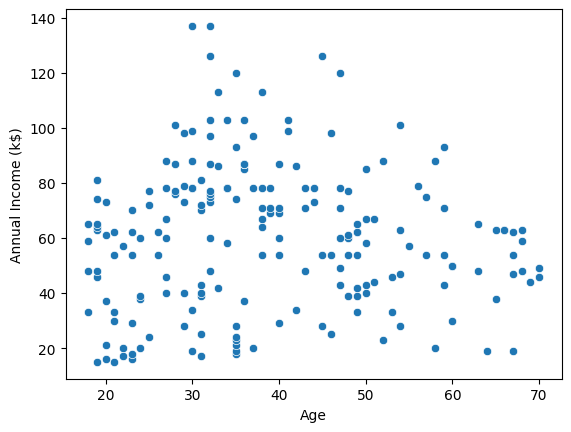

In [4]:
#                                                   Dataset Creation and splitting

customer = ( pd.read_csv(r"D:\VS CODE\Data Science\Machine Learning\10. K Means Clustering\Dataset\Mall_Customers.csv")
            .loc[:, ['Age', 'Annual Income (k$)']]
           )
print(customer)

sns.scatterplot(data = customer, x = 'Age', y = 'Annual Income (k$)')

x_train, x_test = train_test_split(customer, test_size = 0.2, random_state = 42) # (160, 2), (40, 2) shapes dataframe.

In [5]:
#                                            KMeans() training assuming n_clusters.

kmean = KMeans(n_clusters = 3, random_state = 42) # 
y = kmean.fit_predict(X = x_train) # It both trains(fit) and returns the predicting output i.e. cluster_group_no for each input row.

print(x_train.assign(cluster_group_no = y)) # since n_clusters = 3, cluster_group_no is in 0 - 2 range.

print(f"\nWCSS or Inertia for that K Means Clustering model = {kmean.inertia_}.")
print(f"\nThe cluster groups are from {y.min()} to {y.max()} since n_clusters = 3.")

selecting_inertia_groups = """
y = array([ 1, 0, 2, 1, 0, 0, 2, 2, 0, 1, 0, 0, 2, 0, 1, 1, 0, 1, 0, 1, 0, 0,
            2, 1, 2, 1, 1, 0, 1, 0, 2, 0, 0, 2, 1, 0, 2, 0, 0, 0, 2, 1, 1, 0,
            0, 1, 0, 2, 0, 2, 2, 0, 1, 2, 2, 0, 0, 2, 2, 0, 2, 1, 0, 0, 1, 0,
            1, 1, 0, 0, 0, 2, 0, 0, 1, 0, 1, 1, 0, 2, 1, 1, 0, 0, 2, 2, 0, 0,
            1, 2, 0, 2, 0, 0, 2, 0, 2, 0, 1, 0, 0, 0, 0, 2, 1, 1, 2, 1, 0, 1,
            0, 0, 1, 1, 2, 1, 0, 0, 2, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 2, 2, 1,
            2, 1, 0, 0, 0, 2, 0, 0, 2, 2, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 2, 0,
            1, 1, 2, 1, 0, 1])

x_train.loc[y == 0] returns the first  cluster|group.
x_train.loc[y == 1] returns the second cluster|group.
x_train.loc[y == 2] returns the third  cluster|group.
"""

y

     Age  Annual Income (k$)  cluster_group_no
79    49                  54                 1
197   32                 126                 0
38    36                  37                 2
24    54                  28                 1
122   40                  69                 0
..   ...                 ...               ...
106   66                  63                 1
14    37                  20                 2
92    48                  60                 1
179   35                  93                 0
102   67                  62                 1

[160 rows x 3 columns]

WCSS or Inertia for that K Means Clustering model = 48889.958708473314.

The cluster groups are from 0 to 2 since n_clusters = 3.


array([1, 0, 2, 1, 0, 0, 2, 2, 0, 1, 0, 0, 2, 0, 1, 1, 0, 1, 0, 1, 0, 0,
       2, 1, 2, 1, 1, 0, 1, 0, 2, 0, 0, 2, 1, 0, 2, 0, 0, 0, 2, 1, 1, 0,
       0, 1, 0, 2, 0, 2, 2, 0, 1, 2, 2, 0, 0, 2, 2, 0, 2, 1, 0, 0, 1, 0,
       1, 1, 0, 0, 0, 2, 0, 0, 1, 0, 1, 1, 0, 2, 1, 1, 0, 0, 2, 2, 0, 0,
       1, 2, 0, 2, 0, 0, 2, 0, 2, 0, 1, 0, 0, 0, 0, 2, 1, 1, 2, 1, 0, 1,
       0, 0, 1, 1, 2, 1, 0, 0, 2, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 2, 2, 1,
       2, 1, 0, 0, 0, 2, 0, 0, 2, 2, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 2, 0,
       1, 1, 2, 1, 0, 1])

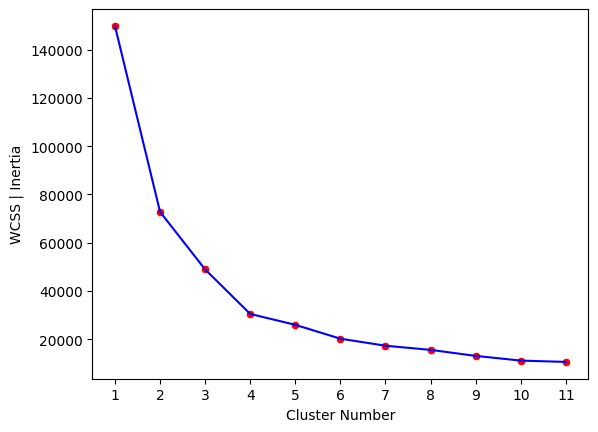

In [6]:
#                                           Finding the optimal n_clusters.

wcss = [KMeans(n_clusters = cluster_number, random_state = 42).fit(X = x_train).inertia_ for cluster_number in range(1, 12)]

ax = sns.scatterplot(x = np.arange(1, 12), y = wcss, color = 'red')
sns.lineplot(x = np.arange(1, 12), y = wcss, color = 'blue')
ax.set_xticks(ticks = np.arange(1, 12))
ax.set_xlabel('Cluster Number')
ax.set_ylabel('WCSS | Inertia')

plt.show()

decision = "We can see after 4 clusters there is no significant changes. So we'll choose n_clusters = 4."

centroids of clusters :

[[ 33.84745763  73.3220339 ]
 [ 56.02325581  48.90697674]
 [ 28.78947368  28.60526316]
 [ 36.3        109.05      ]].


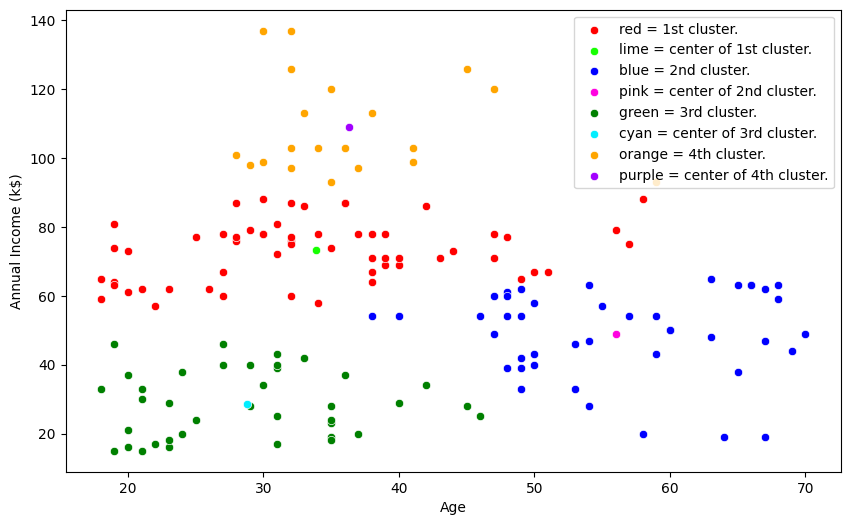

Prediction on x_test = 

     Age  Annual Income (k$)  cluster_group_no cluster_group_name
95    24                  60                 0                red
15    22                  20                 2              green
30    60                  30                 1               blue
158   34                  78                 0                red
128   59                  71                 1               blue
115   19                  65                 0                red
69    32                  48                 2              green
170   40                  87                 0                red
174   52                  88                 0                red
45    24                  39                 2              green
66    43                  48                 1               blue
182   46                  98                 3             orange
165   36                  85                 0                red
78    23                  54                 0     

In [17]:
#                                       Using the n_clusters we quantified in previous codeblock.

kmean = KMeans(n_clusters = 4, random_state = 42)
y = kmean.fit_predict(X = x_train) # It both trains(fit) and returns the predicting output i.e. cluster_group_no for each input row.

print(f"centroids of clusters :\n\n{kmean.cluster_centers_}.")

plt.figure(figsize = (10, 6))
sns.scatterplot(data = x_train.loc[y == 0], x = 'Age', y = 'Annual Income (k$)', color = 'red') # 1st cluster group.
sns.scatterplot(x = [kmean.cluster_centers_[0][0]], y = [kmean.cluster_centers_[0][1]], color = "#16ff01") # centre of 1st cluster.

sns.scatterplot(data = x_train.loc[y == 1], x = 'Age', y = 'Annual Income (k$)', color = 'blue') # 2nd cluster group.
sns.scatterplot(x = [kmean.cluster_centers_[1][0]], y = [kmean.cluster_centers_[1][1]], color = "#ff02e0") # centre of 2nd cluster.

sns.scatterplot(data = x_train.loc[y == 2], x = 'Age', y = 'Annual Income (k$)', color = 'green') # 3rd cluster group.
sns.scatterplot(x = [kmean.cluster_centers_[2][0]], y = [kmean.cluster_centers_[2][1]], color = "#01eeff") # centre of 3rd cluster.

sns.scatterplot(data = x_train.loc[y == 3], x = 'Age', y = 'Annual Income (k$)', color = 'orange') # 4th cluster group.
sns.scatterplot(x = [kmean.cluster_centers_[3][0]], y = [kmean.cluster_centers_[3][1]], color = "#a200ff") # centre of 4th cluster.

plt.legend(['red = 1st cluster.', 'lime = center of 1st cluster.',
            'blue = 2nd cluster.', 'pink = center of 2nd cluster.', 
            'green = 3rd cluster.', 'cyan = center of 3rd cluster.',
            'orange = 4th cluster.', 'purple = center of 4th cluster.'])
plt.show()

print(f"""Prediction on x_test = \n\n{(
            x_test.assign(cluster_group_no = kmean.predict(X = x_test))
           .assign(cluster_group_name = lambda df: df['cluster_group_no'].replace([0,1,2,3], ['red','blue','green','orange']))
                                      )}.""")

#                                           K Means Clustering with ND Data

In [101]:
#                                                   Dataset Creation and splitting

customer1 = ( pd.read_csv(r"D:\VS CODE\Data Science\Machine Learning\10. K Means Clustering\Dataset\Mall_Customers.csv")
             .assign(Gender = lambda df: df['Gender'].astype('category'))
             .assign(Gender = lambda df: df['Gender'].cat.codes) # Male = 1, Female = 0.
)
print(customer1)

x_train1, x_test1 = train_test_split(customer1, test_size = 0.2, random_state = 42) # (160, 2), (40, 2) shapes dataframe.

     CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0             1       1   19                  15                      39
1             2       1   21                  15                      81
2             3       0   20                  16                       6
3             4       0   23                  16                      77
4             5       0   31                  17                      40
..          ...     ...  ...                 ...                     ...
195         196       0   35                 120                      79
196         197       0   45                 126                      28
197         198       1   32                 126                      74
198         199       1   32                 137                      18
199         200       1   30                 137                      83

[200 rows x 5 columns]


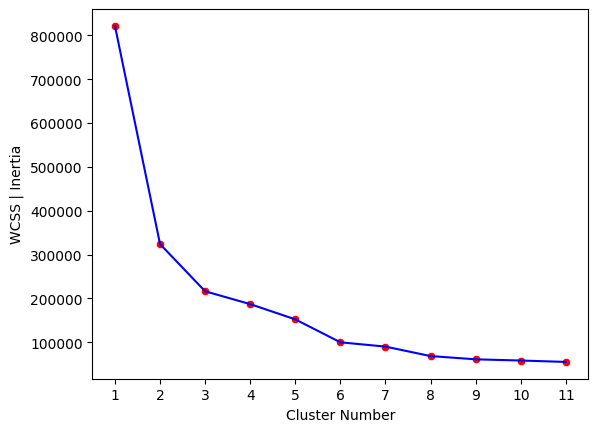

In [103]:
#                                           Finding the optimal n_clusters.

wcss1 = [KMeans(n_clusters = cluster_number, random_state = 42).fit(X = x_train1).inertia_ for cluster_number in range(1, 12)]

ax = sns.scatterplot(x = np.arange(1, 12), y = wcss1, color = 'red')
sns.lineplot(x = np.arange(1, 12), y = wcss1, color = 'blue')
ax.set_xticks(ticks = np.arange(1, 12))
ax.set_xlabel('Cluster Number')
ax.set_ylabel('WCSS | Inertia')

plt.show()

decision = "We can see after 6 clusters there is no significant changes. So we'll choose n_clusters = 6."

In [ ]:
#                                       Using the n_clusters we quantified in previous codeblock.

kmean1 = KMeans(n_clusters = 6, random_state = 42)
y = kmean1.fit_predict(X = x_train1) # It both trains(fit) and returns the predicting output i.e. cluster_group_no for each input row.

to_replace = [  0,    1,      2,      3,        4,        5  ]
values =     ['red','blue','green','orange', 'maroon', 'cyan']

print(f"""Prediction on x_test1 = \n\n{(x_test1.assign(cluster_group_no = kmean1.predict(X = x_test1))
                                       .assign(cluster_group_name = lambda df: df['cluster_group_no'].replace(to_replace, values))
                                       ).to_string()}.""")

Prediction on x_test1 = 

     CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)  cluster_group_no cluster_group_name
95           96       1   24                  60                      52                 3             orange
15           16       1   22                  20                      79                 4             maroon
30           31       1   60                  30                       4                 1               blue
158         159       1   34                  78                       1                 0                red
128         129       1   59                  71                      11                 0                red
115         116       0   19                  65                      50                 3             orange
69           70       0   32                  48                      47                 5               cyan
170         171       1   40                  87                      13                 0    